# Multiple ALPs

Danny Kirkham and Fran Chadha-Day have written a module for ALPRO to account for multiple ALP fields. This notebook contains a brief demonstration. If you use this module, please cite their paper. 

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt 
import numpy as np 
import alpro 
alpro.util.set_default_plot_params()

The basic interface is the same as with a single ALP. We first set up the survival class, but set the ``multi_alp`` keyword to ``True``, which allows us to access the multiple ALP formalism. This scheme calculates eigenvalues and eigenvectors numerically instead of analytically, and allows a general solution for an $(N+2) \times (N+2)$ transfer matrix rather than the specific $3\times3$ version. 

In [2]:
s = alpro.Survival("1275a", multi_alp=True)

The ALP parameters are set using the set_params method just as with the single ALP case, but now arrays can be passed as arguments. 

In [3]:
masses = np.array([1e-12, 5e-13])
couplings = np.array([1e-13, 2e-13]) * 1e-9
s.set_params(g = couplings, mass = masses)

We can again print out what is contained in the survival class at this stage, and we see the get_P function is set to ``get_P_Nalps`` and the g_a and mass variables are array-like: 

In [4]:
for k,v in vars(s).items(): 
    print ("{:20s}  {}".format(k,v))

model                 1275a
coherence_func        <bound method my_powerlaw.rvs of <alpro.util.my_powerlaw object at 0x133cda390>>
N_alps                2
available_models      ['1821', '1275a', '1275b', 'custom', 'file', 'uniform', 'libanov', None]
cluster               <alpro.models.ClusterProfile object at 0x142ddb800>
coherence_r0          None
implementation        numba
_multi_alp            True
get_P                 CPUDispatcher(<function get_P_Nalp at 0x142dc3ce0>)
pol_matrix_bool       False
cmb_qed_term          True
g_a                   [1.e-22 2.e-22]
mass                  [1.e-12 5.e-13]


Let's initialise a simple model and compare the results from multiple ALPS: 

In [5]:
s.init_model()
LMAX = 1800.0
s.domain.create_box_array(LMAX, 42, s.coherence_func, r0=0)

In [6]:
# calculate conversion probabilties
energies = np.logspace(0, 8, 1000)
P_conv, _ = s.propagate(energies=energies)

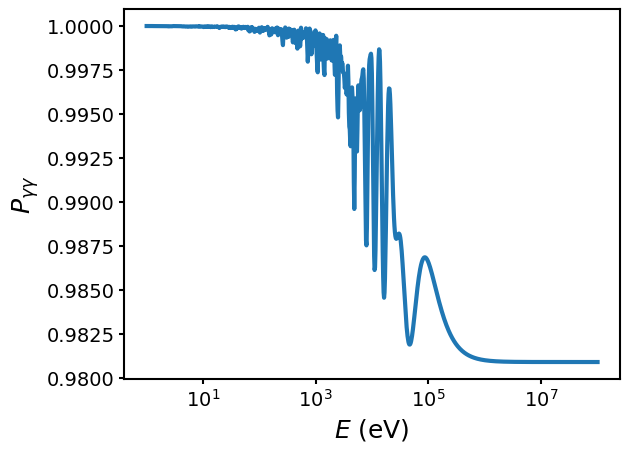

In [7]:
fig = s.default_plot(plot_kwargs = {"lw": 3}, mode="survival")

Looks reasonable, but we can also run two simple tests here. Two ALP fields with different couplings $g_1,g_2$ but the same mass should behave equivalently to one ALP field with a coupling $(g_1+g_2)/sqrt{2}$. Let's check this plays out: 

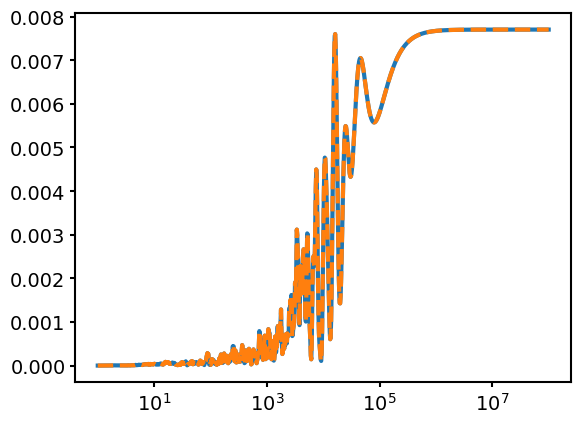

In [8]:
s.multi_alp = True
masses = np.array([1e-12, 1e-12])
g1 = 1e-13 
g2 = 1e-13
couplings = np.array([g1, g2]) * 1e-9
s.set_params(g = couplings, mass = masses)

# calculate conversion probabilties
energies = np.logspace(0, 8, 1000)
P_conv, _ = s.propagate(energies=energies)

s.multi_alp = False 
s.set_params(g = (g1 + g2) * 1e-9 / np.sqrt(2), mass = 1e-12)
P_conv2, _ = s.propagate(energies=energies)
plt.plot(energies, P_conv)
plt.plot(energies, P_conv2, ls="--")
_ = plt.semilogx()

Finally as a test of purely the numerical implementation of the Eigenvectors, we can check that one ALP field in the multi_alp scheme gives the same (within some tolerance) answer as the original ALPRO:

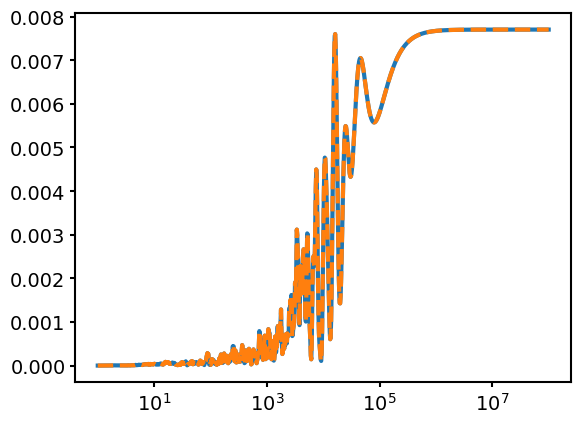

In [9]:
s.multi_alp = True 
s.set_params(g = (g1 + g2) * 1e-9 / np.sqrt(2), mass = 1e-12)
P_conv3, _ = s.propagate(energies=energies)
plt.plot(energies, P_conv2)
plt.plot(energies, P_conv3, ls="--")
_ = plt.semilogx()

All is well! Related versions of these last two tests are included in the ALPRO unit tests. 